# 02 - Model training and evaluation
**Project 4: Customer Review Intelligence** - PDF steps 5-6: classical ML baselines, then a fine-tuned transformer.

| Step | Module | Key outputs |
|---|---|---|
| 5. Classical ML | `reviews.train_classical` | `reports/model_comparison.csv`, `models/classical_best.joblib` |
| 6. DistilBERT | `reviews.train_transformer` | `reports/transformer_results.json`, `models/distilbert_sentiment/` |

Both use the **same** stratified split, so their scores are directly comparable.

## 0. Setup
Flags default to `False` (read saved results). Fine-tuning needs an NVIDIA GPU and takes a while.

In [1]:
import json
import logging
import os
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

# Notebooks live in notebooks/, the project root is one level up (the modules and data paths are relative to it).
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)

from reviews.config import ProjectConfig
from reviews.logging_utils import configure_logging

configure_logging("WARNING")                      # keep the notebook quiet; use "INFO" to watch the pipeline
base = ProjectConfig()
CFG = replace(base, paths=replace(base.paths, root=ROOT))
pd.set_option("display.max_columns", 30, "display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("Project root:", ROOT)

import joblib

RUN_CLASSICAL = False       # about 10-30 minutes on CPU
RUN_TRANSFORMER = False     # needs a CUDA GPU (about 15-25 minutes on an RTX 5070)

def read_json(path: Path) -> dict:
    """Read a saved report, or stop with a hint about which step creates it."""
    if not path.is_file():
        raise FileNotFoundError(f"{path} not found; set the matching RUN_ flag to True (or run the earlier steps first).")
    return json.loads(path.read_text(encoding="utf-8"))

TARGET = CFG.targets.macro_f1_binary
print("Target macro-F1 (binary):", TARGET)

Project root: c:\Projects\review-intelligence-nlp
Target macro-F1 (binary): 0.88


## 1. The split
Binary task (positive vs negative), stratified 70/15/15 with `random_state=42`. Train fits models, validation
picks hyper-parameters (and the DistilBERT threshold), test is touched once for the final numbers.

In [2]:
from reviews import classical

frame = pd.read_parquet(CFG.paths.text_path(sample=False), columns=["Id", "Text", "text_clean", "sentiment", "review_date", "Score"])
binary = classical.binary_frame(frame, CFG.labels)
train, val, test = classical.stratified_split(binary, CFG.split)
sizes = pd.DataFrame({"rows": [len(train), len(val), len(test)],
                      "positive_share": [(d["sentiment"] == "positive").mean().round(4) for d in (train, val, test)]},
                     index=["train", "validation", "test"])
sizes

,rows,positive_share
train,254262,0.8432
validation,54485,0.8432
test,54485,0.8432


## 2. Classical models (step 5)
TF-IDF (word and word+bigram) and bag-of-words features with Logistic Regression, Linear SVM and Naive Bayes, plus a
majority-class baseline that shows what "doing nothing" scores. Regularisation strength is tuned on validation.

In [3]:
if RUN_CLASSICAL:
    from reviews import train_classical
    train_classical.run(CFG)
classical_results = read_json(CFG.paths.reports_path / f"{CFG.classical.results_name}.json")
comparison = pd.read_csv(CFG.paths.reports_path / f"{CFG.classical.comparison_name}.csv")
comparison.sort_values("test_macro_f1", ascending=False)

,model,features,best_param,val_macro_f1,test_accuracy,test_macro_f1,f1_negative,f1_positive,tune_fit_seconds,predict_seconds_per_1000
0,tfidf_linear_svm,tfidf,C=1.0,0.8809,0.9350,0.8821,0.8030,0.9611,22.5,0.033
1,tfidf_logreg,tfidf,C=3.0,0.8768,0.9285,0.8760,0.7953,0.9567,4.5,0.028
2,tfidf_naive_bayes,tfidf,alpha=1.0,0.8533,0.9249,0.8538,0.7519,0.9558,1.2,0.029
3,bow_naive_bayes,bow,alpha=0.1,0.8482,0.9118,0.8474,0.7483,0.9465,1.2,0.028
4,majority_class,-,-,NaN,0.8432,0.4575,0.0000,0.9149,0.0,0.000


Best classical model: tfidf_linear_svm | test macro-F1: 0.8821
Majority-class macro-F1 (do-nothing baseline): 0.4575
Best TF-IDF score handed to step 6: 0.8821
Chronological check (train on past, test on future): {'model': 'tfidf_linear_svm', 'train_reviews': 308747, 'test_reviews': 54485, 'train_until': '2012-06-30', 'test_from': '2012-06-30', 'test_positive_share': 0.829, 'accuracy': 0.9335, 'macro_f1': 0.8865}


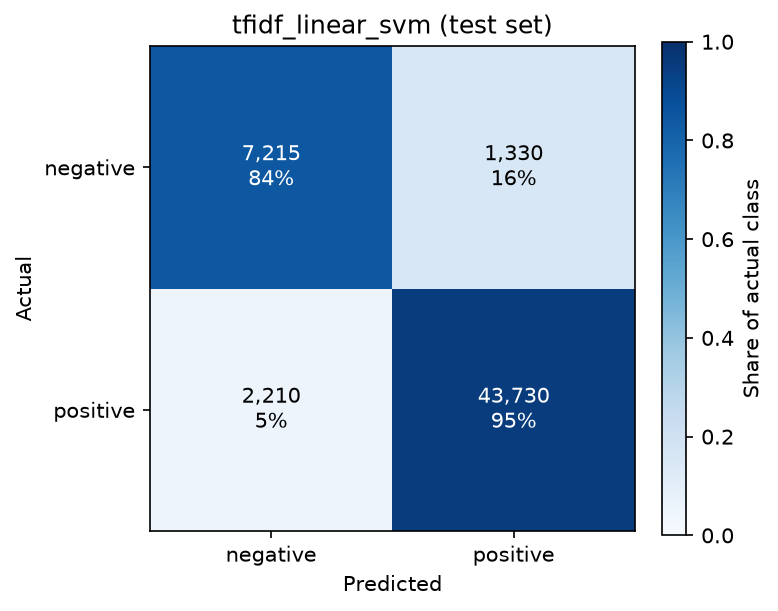

In [4]:
print("Best classical model:", classical_results["best_model"], "| test macro-F1:", round(classical_results["best_test_macro_f1"], 4))
print("Majority-class macro-F1 (do-nothing baseline):", round(classical_results["majority_class_macro_f1"], 4))
print("Best TF-IDF score handed to step 6:", round(classical_results["tfidf_baseline_macro_f1_for_step6"], 4))
if "chronological_check" in classical_results:
    print("Chronological check (train on past, test on future):", classical_results["chronological_check"])
display(Image(filename=str(CFG.paths.figures_path / "confusion_matrix_classical.png")))

### What the linear model learned
Top terms by coefficient from TF-IDF + Logistic Regression: a sanity check that the model uses sensible words.

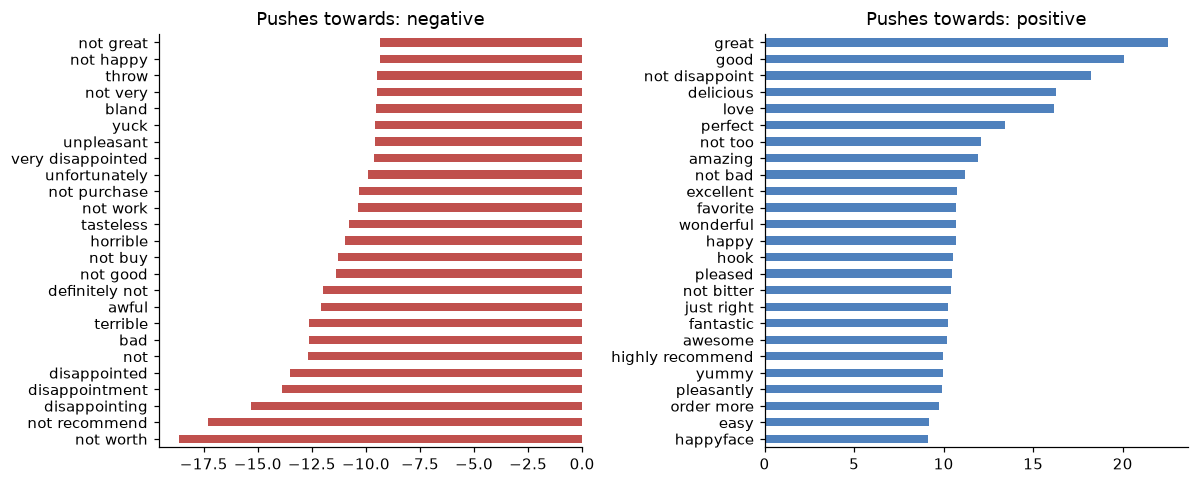

In [5]:
terms = classical_results["top_terms"]
fig, axes = plt.subplots(1, len(terms), figsize=(11, 4.5))
for ax, (label, weights) in zip(np.atleast_1d(axes), terms.items()):
    s = pd.Series(weights).sort_values()
    s.plot.barh(ax=ax, color="#4f81bd" if "pos" in label else "#c0504d", title=f"Pushes towards: {label}")
plt.tight_layout(); plt.show()

## 3. Fine-tuned DistilBERT (step 6)
`distilbert-base-uncased` fine-tuned on the **raw** review text (max 256 tokens, 2 epochs, bf16, batch 32,
learning rate 2e-5) with the Hugging Face `Trainer`. The probability threshold is tuned on the validation set,
never on test. The model is "worth the cost" only if it beats the best TF-IDF model by at least 0.01 macro-F1.

In [6]:
import torch
print("PyTorch", torch.__version__, "| CUDA:", torch.cuda.is_available(), "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no GPU")
if RUN_TRANSFORMER:
    from reviews import train_transformer
    train_transformer.run(CFG)
tr = read_json(CFG.paths.reports_path / f"{CFG.transformer.results_name}.json")
tuned = tr["tuned_threshold"]
print(f"Test macro-F1: {tuned['macro_f1']:.4f} (default 0.5 threshold: {tr['default_threshold']['macro_f1']:.4f}; tuned threshold {tr['threshold']})")
print("Meets the target:", tr["meets_target"], "| gain over best TF-IDF:", tr.get("gain_over_tfidf"), "| worth the cost:", tr.get("worth_the_cost"))
print(f"Training time {tr['train_minutes']} min | inference {tr['predict_seconds_per_1000']} s per 1,000 reviews")
pd.DataFrame(tuned["per_class"]).T

PyTorch 2.11.0+cu128 | CUDA: True | NVIDIA GeForce RTX 5070
Test macro-F1: 0.9407 (default 0.5 threshold: 0.9404; tuned threshold 0.53)
Meets the target: True | gain over best TF-IDF: 0.0586 | worth the cost: True
Training time 18.2 min | inference 0.633 s per 1,000 reviews


,precision,recall,f1,support
negative,0.903885,0.895846,0.899847,8545.0
positive,0.980659,0.982281,0.981469,45940.0


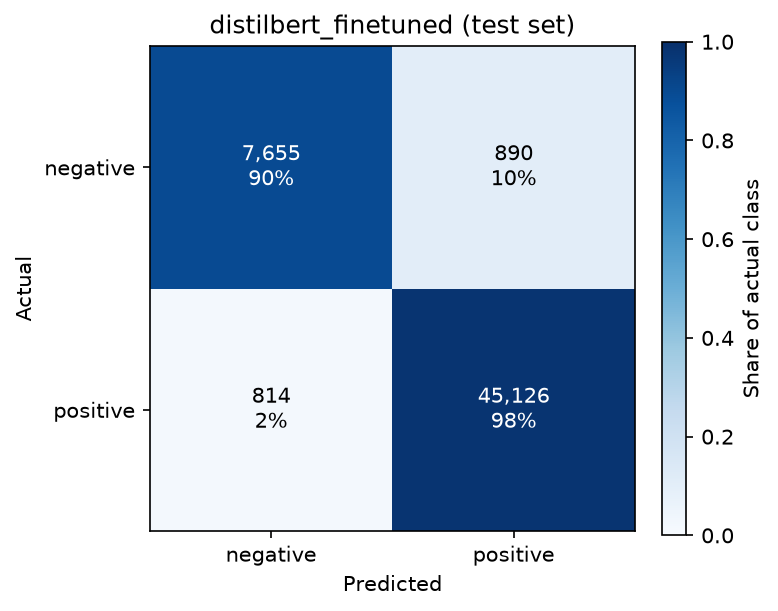

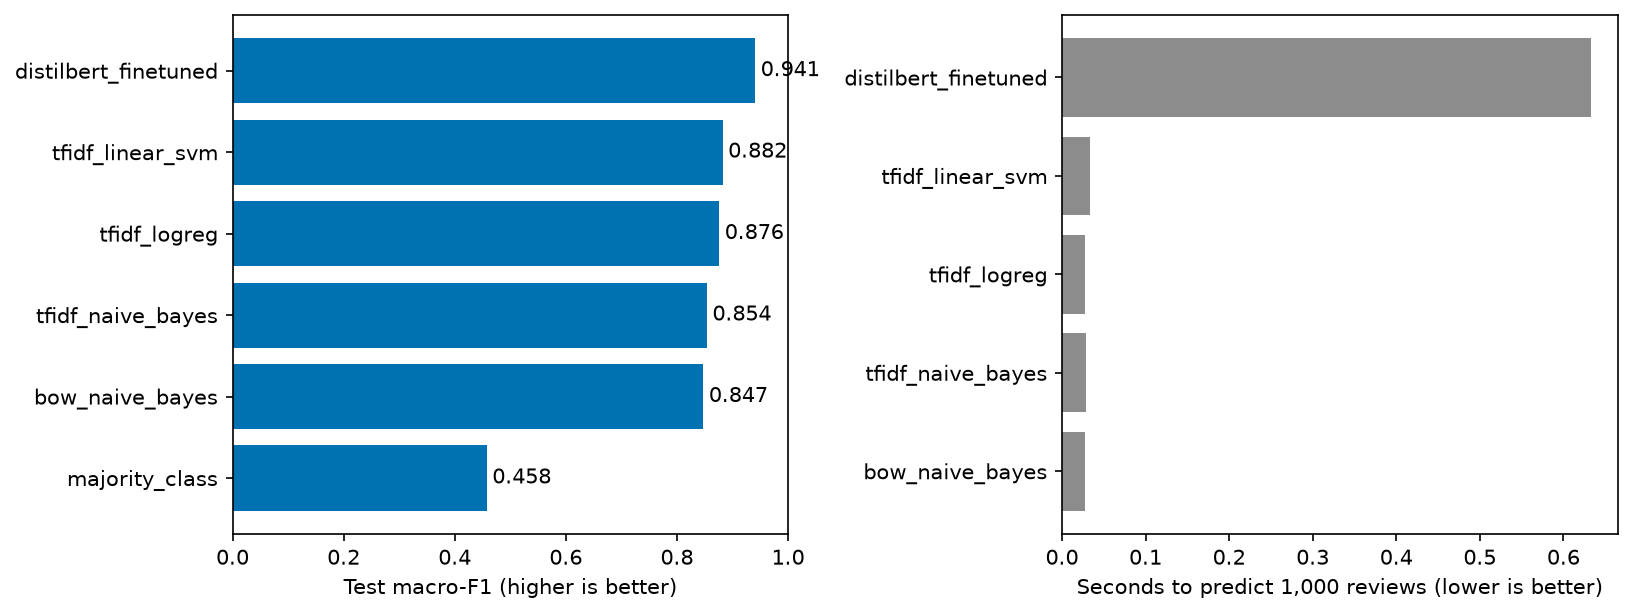

In [7]:
display(Image(filename=str(CFG.paths.figures_path / "confusion_matrix_transformer.png")))
display(Image(filename=str(CFG.paths.figures_path / "model_comparison_all.png")))

## 4. All models side by side

In [8]:
final = pd.read_csv(CFG.paths.reports_path / f"{CFG.transformer.comparison_name}.csv")
final.sort_values("test_macro_f1", ascending=False).reset_index(drop=True)

,model,features,best_param,val_macro_f1,test_accuracy,test_macro_f1,f1_negative,f1_positive,tune_fit_seconds,predict_seconds_per_1000
0,distilbert_finetuned,raw text (subword tokens),threshold=0.53,0.9409,0.9687,0.9407,0.8998,0.9815,1092.8,0.633
1,tfidf_linear_svm,tfidf,C=1.0,0.8809,0.9350,0.8821,0.8030,0.9611,22.5,0.033
2,tfidf_logreg,tfidf,C=3.0,0.8768,0.9285,0.8760,0.7953,0.9567,4.5,0.028
3,tfidf_naive_bayes,tfidf,alpha=1.0,0.8533,0.9249,0.8538,0.7519,0.9558,1.2,0.029
4,bow_naive_bayes,bow,alpha=0.1,0.8482,0.9118,0.8474,0.7483,0.9465,1.2,0.028
5,majority_class,-,-,NaN,0.8432,0.4575,0.0000,0.9149,0.0,0.000


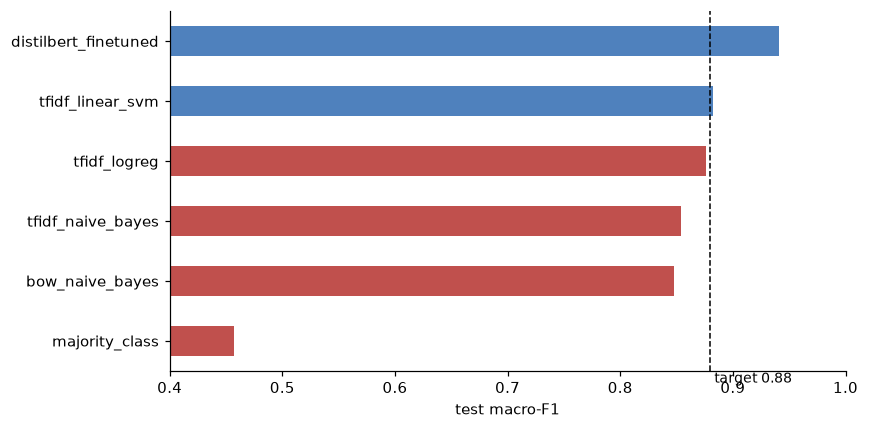

In [9]:
final_sorted = final.sort_values("test_macro_f1")
colors = ["#c0504d" if v <= TARGET else "#4f81bd" for v in final_sorted["test_macro_f1"]]
ax = final_sorted.plot.barh(x="model", y="test_macro_f1", color=colors, legend=False, figsize=(8, 4))
ax.axvline(TARGET, color="black", ls="--", lw=1)
ax.text(TARGET, -0.7, f" target {TARGET}", fontsize=9)
ax.set_xlim(0.4, 1); ax.set_xlabel("test macro-F1"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

## 5. Does the score hold up over time?
The split is random, so we also check the newest slice of reviews: a model that only works on old data would fail in production.

In [10]:
slices = tr.get("time_slices")
if slices:
    display(pd.json_normalize(slices) if isinstance(slices, list) else pd.json_normalize(slices, sep=" / "))
else:
    print("No time-slice results in the saved report.")

,reviews_per_slice,oldest / from,oldest / to,oldest / positive_share,oldest / macro_f1 / distilbert_finetuned,oldest / macro_f1 / tfidf_best,newest / from,newest / to,newest / positive_share,newest / macro_f1 / distilbert_finetuned,newest / macro_f1 / tfidf_best
0,18162,1999-10-25,2010-11-12,0.8699,0.9331,0.8704,2012-01-17,2012-10-26,0.8245,0.9467,0.8914


## 6. Where the model is confidently wrong
The most confident mistakes are usually label noise (a 1-star review that praises the product) or sarcasm. Reading them tells you what the remaining errors are.

In [11]:
errors = pd.read_csv(CFG.paths.reports_path / f"{CFG.transformer.errors_name}.csv")
pd.set_option("display.max_colwidth", 160)
errors.head(10)

,Id,Score,sentiment,Summary,Text,predicted,confidence
0,513948,1,negative,Purely enjoyable.,This assortment of decaf tea is a delight I look forward to in the evening. The flavors are especially refreshing and varied. My mood dictates which one I...,positive,0.9998
1,154849,1,negative,Yummy,These are so good I have them for breakfast an sometimes lunch I also have one for a snack they give me energy to finish my day,positive,0.9998
2,422425,2,negative,Viva Amazon!!,"Your service is the best. My package arrived promptly, and very well packaged -- it was glass -- very important. And the product is exactly as advertized ...",positive,0.9998
3,102525,1,negative,Make's Your Coffee a Dessert With Fabulous Torani Syrup,"I love Torani Syrup. The flavor is rich and comes thru with every, in my case, cup of coffee. Coffee just is the great without Torani.",positive,0.9998
4,512565,2,negative,EASY TO USE,This is pretty good and very easy to use. I tried the honey mustard and the balsamic vinaigrette. It comes with recipes for several different dressings tha...,positive,0.9998
5,269556,1,negative,GreAT dog treats,These are wonderful dog treats. My dogs really love these. I have been giving my dogs these treats for a long time and they won't eat any other treats.,positive,0.9998
6,309941,1,negative,disgusting,"I tried this chocolate after I saw it on the Martha Stewart Show. I usually expect ""Milk chocolates"" to be sweeter, which is not the case with this chocolat...",positive,0.9997
7,467436,2,negative,"Great Taste, small portion!",This coffee has great bold flavor - a great breakfast coffee. It takes 2 pods to fill a normal sized mug - it would be great if they used the Starbucks / H...,positive,0.9997
8,128854,2,negative,still reviewing,I haven't used this enough yet to decide how I feel but so far so good. Just need a little more time,positive,0.9997
9,506508,1,negative,Romulan Ale,This product is not a toy. It is a real energy drink with the Imfamis Title Romulan Ale. It Tastes great and was rare gift I could present to a fellow Trekker.,positive,0.9997


## 7. Try the saved models
Quick predictions from the artefacts the Streamlit app uses.

In [12]:
from reviews import predict

samples = [
    "Absolutely delicious, arrived fresh and the price was great.",
    "Stale and bland. The box was crushed and shipping took three weeks.",
    "It is a bag of coffee beans.",
]
model_dir = CFG.paths.models_path / CFG.transformer.model_dir
scorer = predict.load_scorer(model_dir, CFG.transformer.max_length, 16, require_cuda=False)
p = scorer(samples)
labels = predict.label_probabilities(p, predict.read_threshold(model_dir), CFG.aspects)
pd.DataFrame({"review": samples, "p_positive": p.round(3), "label": labels})

c:\Projects\review-intelligence-nlp\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1125 08:52:23.065000 33148 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
Loading weights: 100%|██████████| 104/104 [00:00<00:00, 1680.91it/s]


,review,p_positive,label
0,"Absolutely delicious, arrived fresh and the price was great.",1.000,positive
1,Stale and bland. The box was crushed and shipping took three weeks.,0.001,negative
2,It is a bag of coffee beans.,0.941,positive


In [13]:
pipeline = joblib.load(CFG.paths.models_path / f"{CFG.classical.model_name}.joblib")
pd.DataFrame({"review": samples, "classical_prediction": pipeline.predict(pd.Series(samples))})

,review,classical_prediction
0,"Absolutely delicious, arrived fresh and the price was great.",positive
1,Stale and bland. The box was crushed and shipping took three weeks.,positive
2,It is a bag of coffee beans.,positive


## 8. Conclusions
* The majority-class baseline shows how much of the score comes from class imbalance alone.
* The best TF-IDF model sets the classical benchmark; DistilBERT's gain over it is reported against the 0.01 "worth the cost" rule.
* The fine-tuned model is published to the Hugging Face Hub and served by the Streamlit app.

Next steps in the repo: topic modelling (`reviews.run_topics`), aspect insights (`reviews.insights`), summaries (`reviews.summarize`).